# AIN429 – Assignment 4

## 1. Dataset Import and Preprocessing

The following libraries are imported for data analysis,
preprocessing, and modeling steps used throughout the notebook.

In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix



In [69]:
df = pd.read_csv("data_4.csv")
df.head()

,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,...,0.0,29729182.96,29729182.96,29729182.96,29729182.96,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,...,0.0,29855277.06,29855277.06,29855277.06,29855277.06,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,...,0.0,29842149.02,29842149.02,29842149.02,29842149.02,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,...,0.0,29913774.97,29913774.97,29913774.97,29913774.97,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,...,0.0,29814704.90,29814704.90,29814704.90,29814704.90,0.0,64240,26847,502,MQTT_Publish


The dataset consists of network flow-level features extracted
from traffic data. Each row represents a single network flow,
and the target variable `Attack_type` indicates the type of
network attack associated with the flow.

The dataset contains a large number of features, which may pose
challenges for clustering algorithms due to the curse of dimensionality.

In [70]:
df.shape

(28458, 84)

- The dataset was checked for missing values and none were found.

In [71]:
df.isnull().sum().sum()

0

In [72]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id.orig_p,28458.0,4.757986e+04,1.011218e+04,0.0,39762.250000,48901.000000,55460.000000,6.544600e+04
id.resp_p,28458.0,4.318306e+03,1.026338e+04,0.0,53.000000,443.000000,2317.500000,6.538900e+04
flow_duration,28458.0,1.648120e+01,2.700244e+02,0.0,0.000006,0.028759,1.295485,2.172834e+04
fwd_pkts_tot,28458.0,6.489282e+00,4.620998e+01,0.0,1.000000,2.000000,9.000000,4.345000e+03
bwd_pkts_tot,28458.0,5.275283e+00,6.856840e+01,0.0,1.000000,2.000000,5.000000,1.011200e+04
...,...,...,...,...,...,...,...,...
idle.avg,28458.0,7.203174e+06,1.763785e+07,0.0,0.000000,0.000000,0.000000,3.000000e+08
idle.std,28458.0,1.968532e+05,2.263456e+06,0.0,0.000000,0.000000,0.000000,1.208029e+08
fwd_init_window_size,28458.0,2.625916e+04,3.143151e+04,0.0,0.000000,1024.000000,64240.000000,6.553500e+04
bwd_init_window_size,28458.0,1.185301e+04,1.806234e+04,0.0,0.000000,0.000000,26847.000000,6.553500e+04


The summary statistics indicate that many features are highly skewed
and span multiple orders of magnitude, motivating the use of feature
scaling before model training and clustering.

- Time-based features exhibit heavy-tailed distributions,
which is expected in network traffic data.

In [73]:
df.describe().T.sort_values("max", ascending=False).head(10)

,count,mean,std,min,25%,50%,75%,max
fwd_iat.tot,28458.0,1.635420e+07,2.699513e+08,0.0,0.000000,238.895416,1.294033e+06,2.172834e+10
flow_iat.tot,28458.0,1.648557e+07,2.700248e+08,0.0,5.960464,28759.121895,1.300128e+06,2.172834e+10
idle.tot,28458.0,1.521828e+07,2.553889e+08,0.0,0.000000,0.000000,0.000000e+00,2.096777e+10
bwd_iat.tot,28458.0,7.700296e+06,1.896004e+08,0.0,0.000000,2803.444863,1.024180e+06,1.876117e+10
active.tot,28458.0,1.267289e+06,3.004122e+07,0.0,5.960464,28021.574020,9.121008e+05,2.945221e+09
active.max,28458.0,7.726185e+05,6.227761e+06,0.0,5.960464,27979.016305,9.072935e+05,8.480979e+08
active.std,28458.0,1.018231e+05,3.072803e+06,0.0,0.000000,0.000000,0.000000e+00,4.774862e+08
active.avg,28458.0,6.408645e+05,3.307654e+06,0.0,5.960464,27960.538865,8.820416e+05,4.374931e+08
active.min,28458.0,5.760535e+05,2.108385e+06,0.0,5.960464,26564.598085,8.536679e+05,3.125080e+08
fwd_iat.max,28458.0,7.447958e+06,1.805140e+07,0.0,0.000000,237.941742,3.192692e+05,3.002526e+08


Features with extremely high variance further increase the difficulty
of distance-based clustering methods, reinforcing the need for feature
scaling and dimensionality-aware analysis.

In [74]:
df.describe().T.sort_values("std", ascending=False).head(10)

,count,mean,std,min,25%,50%,75%,max
flow_iat.tot,28458.0,1.648557e+07,2.700248e+08,0.0,5.960464,28759.121895,1.300128e+06,2.172834e+10
fwd_iat.tot,28458.0,1.635420e+07,2.699513e+08,0.0,0.000000,238.895416,1.294033e+06,2.172834e+10
idle.tot,28458.0,1.521828e+07,2.553889e+08,0.0,0.000000,0.000000,0.000000e+00,2.096777e+10
bwd_iat.tot,28458.0,7.700296e+06,1.896004e+08,0.0,0.000000,2803.444863,1.024180e+06,1.876117e+10
active.tot,28458.0,1.267289e+06,3.004122e+07,0.0,5.960464,28021.574020,9.121008e+05,2.945221e+09
idle.max,28458.0,7.363120e+06,1.812949e+07,0.0,0.000000,0.000000,0.000000e+00,3.000000e+08
flow_iat.max,28458.0,7.467129e+06,1.809213e+07,0.0,5.960464,26697.635650,2.915958e+05,3.000000e+08
fwd_iat.max,28458.0,7.447958e+06,1.805140e+07,0.0,0.000000,237.941742,3.192692e+05,3.002526e+08
idle.avg,28458.0,7.203174e+06,1.763785e+07,0.0,0.000000,0.000000,0.000000e+00,3.000000e+08
idle.min,28458.0,6.994086e+06,1.726672e+07,0.0,0.000000,0.000000,0.000000e+00,3.000000e+08


Large differences between mean and median values indicate highly skewed,
non-normal distributions, further confirming the presence of extreme
values and heterogeneous traffic behavior.

In [75]:
stats = df.describe().T
stats["mean_median_diff"] = (stats["mean"] - stats["50%"]).abs()
stats.sort_values("mean_median_diff", ascending=False).head(10)

,count,mean,std,min,25%,50%,75%,max,mean_median_diff
flow_iat.tot,28458.0,1.648557e+07,2.700248e+08,0.0,5.960464,28759.121895,1.300128e+06,2.172834e+10,1.645681e+07
fwd_iat.tot,28458.0,1.635420e+07,2.699513e+08,0.0,0.000000,238.895416,1.294033e+06,2.172834e+10,1.635396e+07
idle.tot,28458.0,1.521828e+07,2.553889e+08,0.0,0.000000,0.000000,0.000000e+00,2.096777e+10,1.521828e+07
bwd_iat.tot,28458.0,7.700296e+06,1.896004e+08,0.0,0.000000,2803.444863,1.024180e+06,1.876117e+10,7.697493e+06
fwd_iat.max,28458.0,7.447958e+06,1.805140e+07,0.0,0.000000,237.941742,3.192692e+05,3.002526e+08,7.447720e+06
flow_iat.max,28458.0,7.467129e+06,1.809213e+07,0.0,5.960464,26697.635650,2.915958e+05,3.000000e+08,7.440432e+06
idle.max,28458.0,7.363120e+06,1.812949e+07,0.0,0.000000,0.000000,0.000000e+00,3.000000e+08,7.363120e+06
idle.avg,28458.0,7.203174e+06,1.763785e+07,0.0,0.000000,0.000000,0.000000e+00,3.000000e+08,7.203174e+06
idle.min,28458.0,6.994086e+06,1.726672e+07,0.0,0.000000,0.000000,0.000000e+00,3.000000e+08,6.994086e+06
fwd_iat.std,28458.0,2.498669e+06,6.295647e+06,0.0,0.000000,0.000000,1.602429e+05,2.122965e+08,2.498669e+06


Outliers were intentionally retained, as extreme values may represent
legitimate attack behaviors rather than measurement noise.

In [76]:
df["Attack_type"].value_counts()

Attack_type
Thing_Speak                   8108
ARP_poisioning                7750
MQTT_Publish                  4146
NMAP_UDP_SCAN                 2590
NMAP_XMAS_TREE_SCAN           2010
NMAP_OS_DETECTION             2000
NMAP_TCP_scan                 1002
DDOS_Slowloris                 534
Wipro_bulb                     253
Metasploit_Brute_Force_SSH      37
NMAP_FIN_SCAN                   28
Name: count, dtype: int64

### The dataset is highly imbalanced across attack types. While some attacks such as Thing_Speak and ARP_poisioning have thousands of samples, others contain very few instances. Therefore, evaluation metrics beyond accuracy are required.

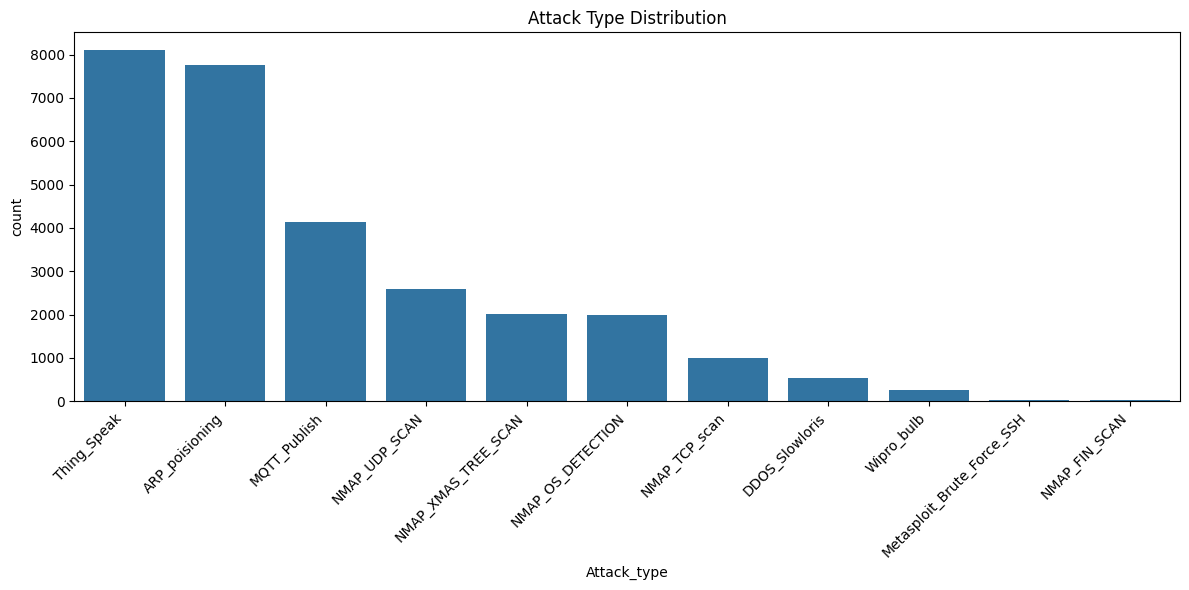

In [77]:
plt.figure(figsize=(12,6))
sns.countplot(
    data=df,
    x="Attack_type",
    order=df["Attack_type"].value_counts().index
)
plt.xticks(rotation=45, ha="right")
plt.title("Attack Type Distribution")
plt.tight_layout()
plt.show()

The distribution shows a strong class imbalance, with some attack
types having only a few samples, which motivates the use of
precision, recall, and F1-score in model evaluation.

A small subset of representative features was selected for visualization
to clearly illustrate the statistical characteristics of the dataset.

In [78]:
eda_features = [
    "flow_duration",      
    "fwd_pkts_tot",       
    "bwd_pkts_tot",      
    "flow_iat.tot",       
    "active.tot",         
    "idle.tot"            
]

Most flows have very small values, while a few flows have extremely large values,
indicating highly skewed distributions typical of network attack data.

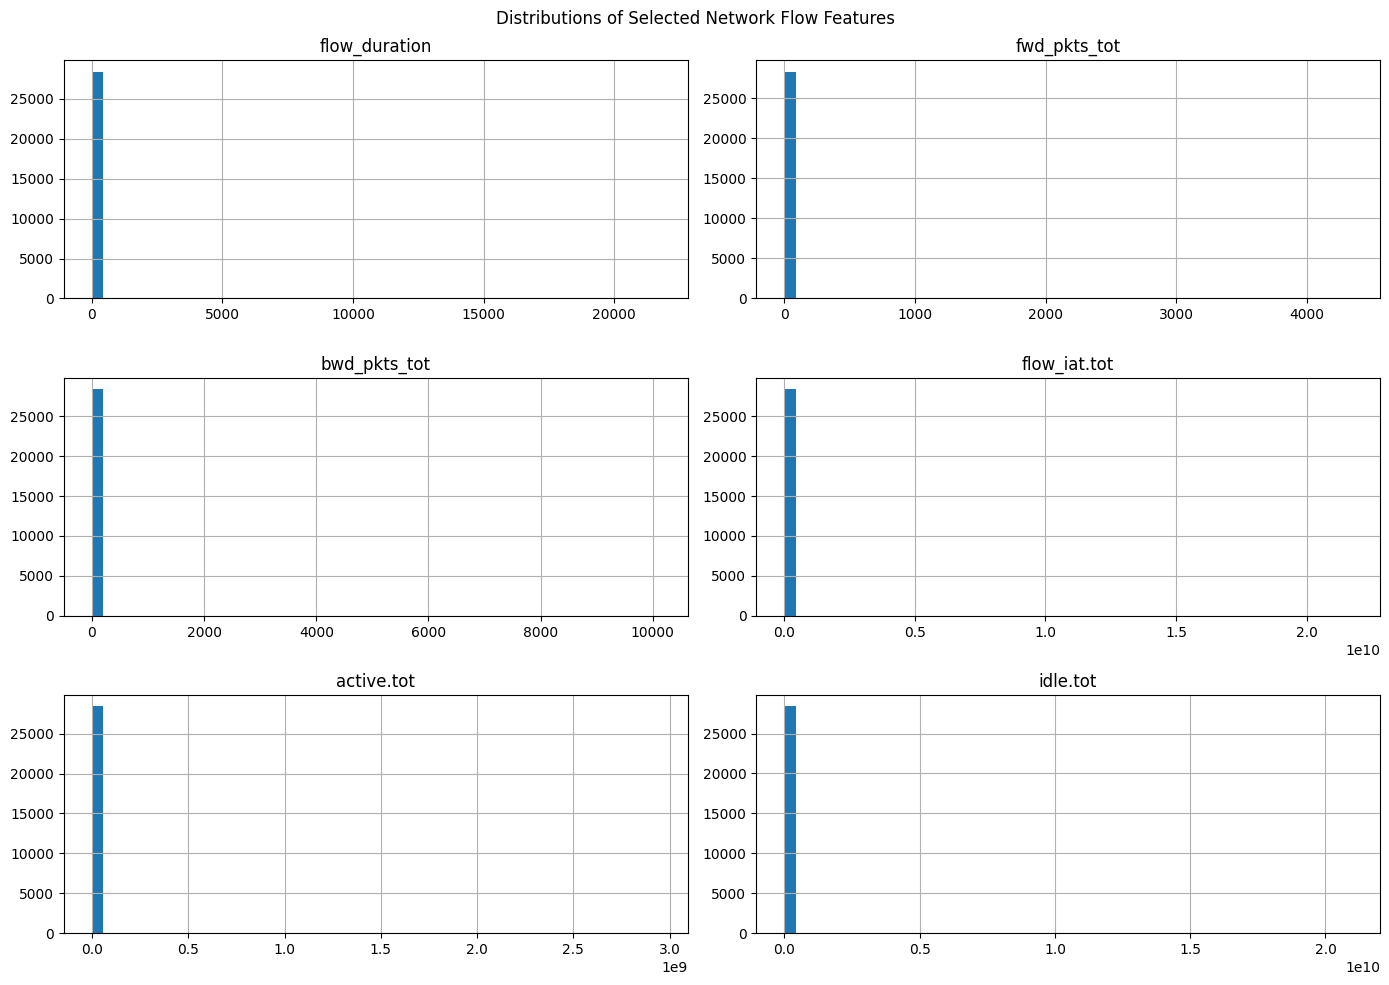

In [79]:
df[eda_features].hist(figsize=(14,10), bins=50)
plt.suptitle("Distributions of Selected Network Flow Features")
plt.tight_layout()
plt.show()

The correlation matrix reveals strong redundancy among time-based features
such as flow_duration, flow_iat.tot, and idle.tot.
While this redundancy does not severely affect tree-based classifiers,
it can negatively impact distance-based clustering algorithms.

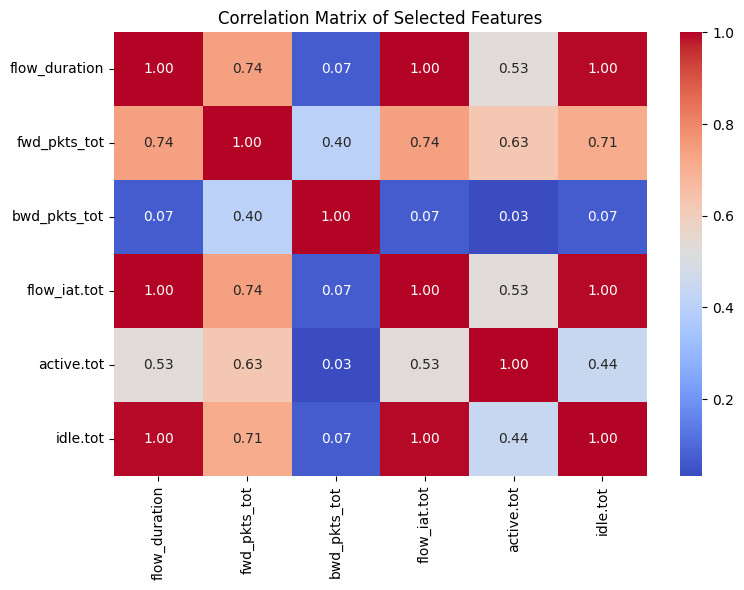

In [80]:
plt.figure(figsize=(8,6))
sns.heatmap(
    df[eda_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix of Selected Features")
plt.tight_layout()
plt.show()

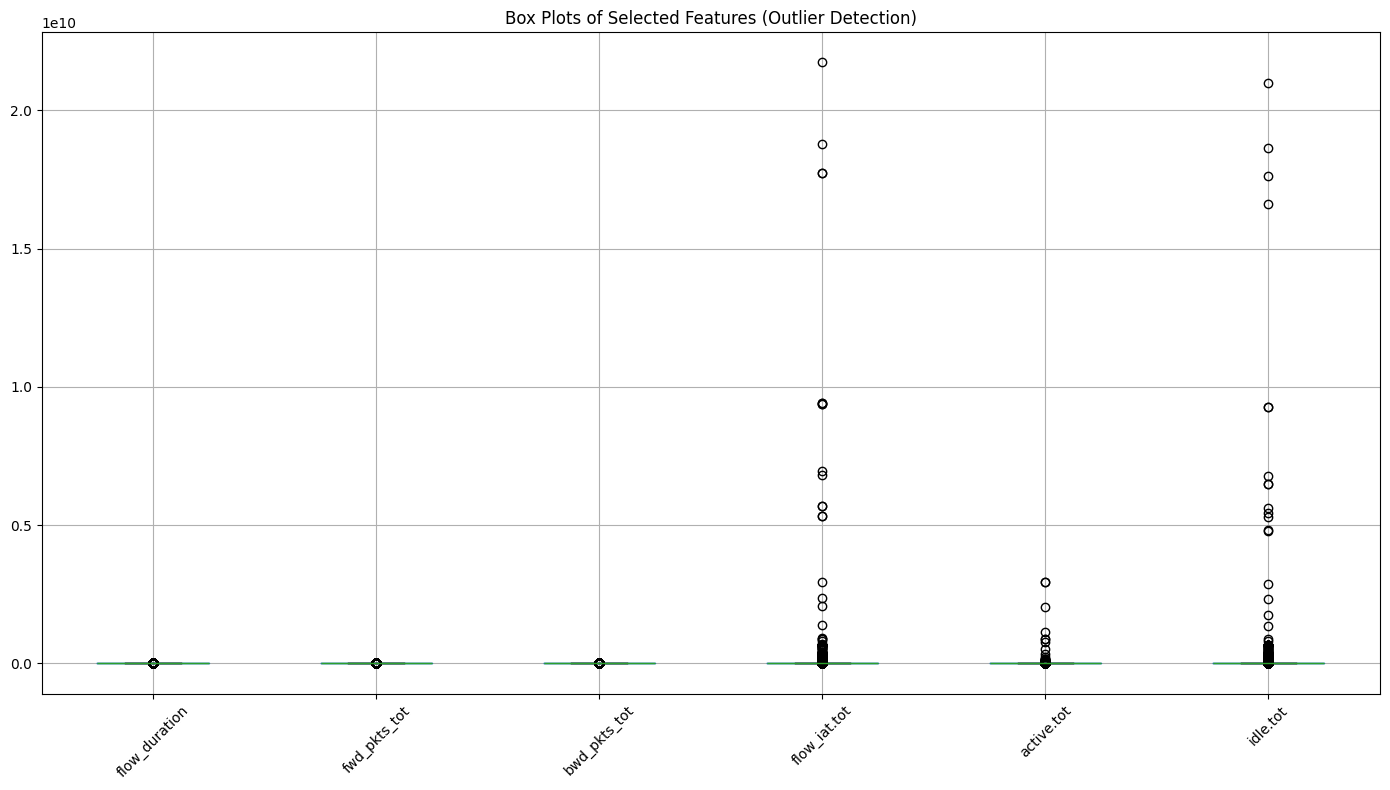

In [81]:
plt.figure(figsize=(14,8))
df[eda_features].boxplot()
plt.title("Box Plots of Selected Features (Outlier Detection)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Box plots highlight the presence of significant outliers, particularly in flow-based features.
These outliers are crucial for detecting anomalies but require robust scaling methods.

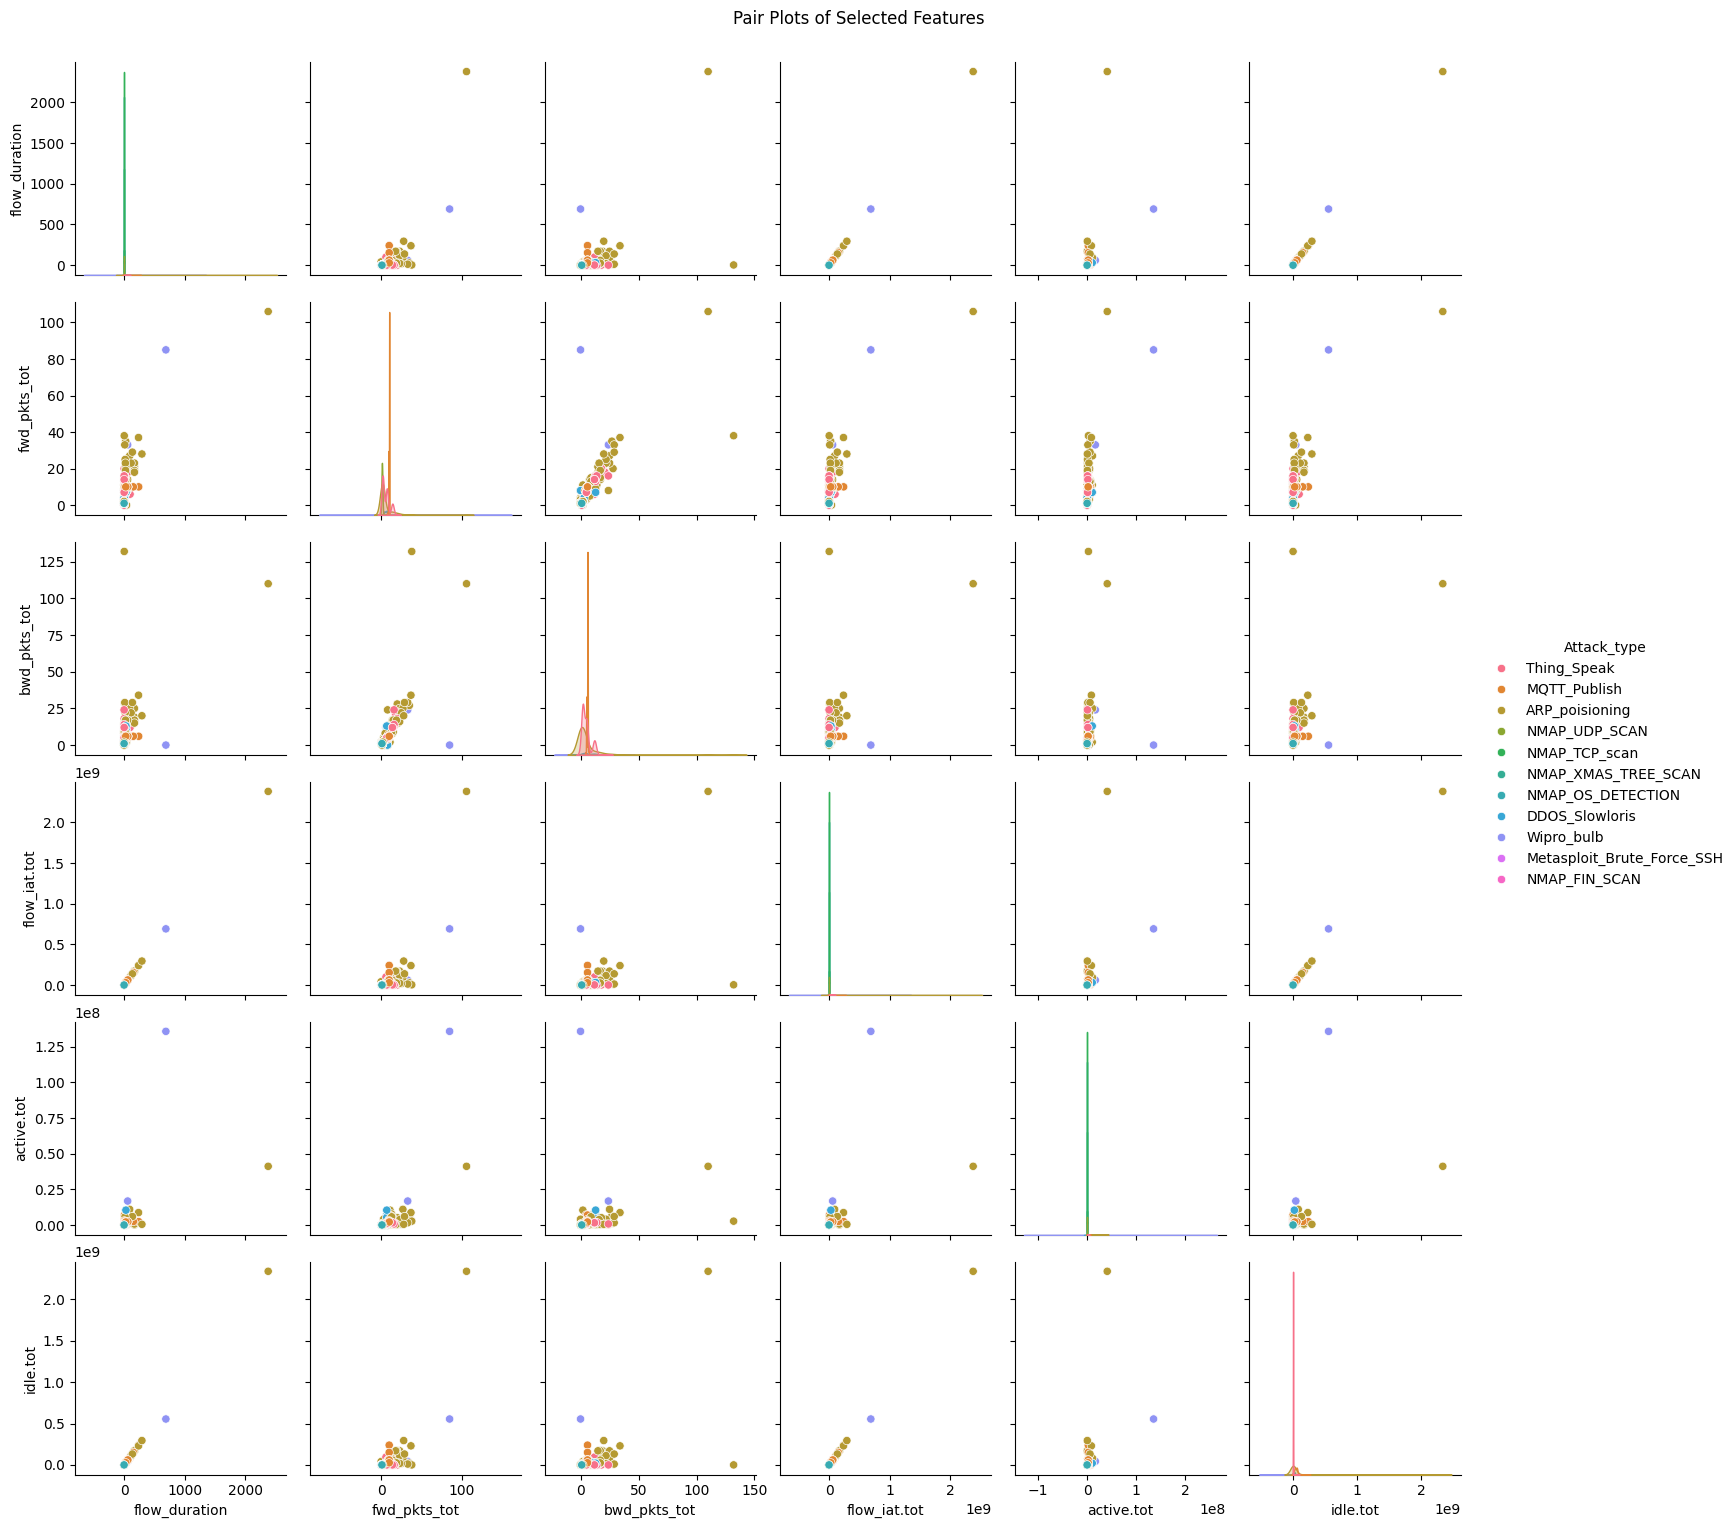

In [82]:
sns.pairplot(
    df[eda_features + ["Attack_type"]].sample(1000, random_state=42),
    hue="Attack_type",
    diag_kind="kde"
)
plt.suptitle("Pair Plots of Selected Features", y=1.02)
plt.show()

Pair plots demonstrate separability between certain classes based on feature combinations.
While some overlap exists, distinct clusters for specific attack types are visible.

In [83]:
X = df.drop("Attack_type", axis=1)
y = df["Attack_type"]

In [84]:
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X.select_dtypes(exclude=["object", "category"]).columns.tolist()

cat_cols, num_cols, (len(cat_cols), len(num_cols))

(['proto', 'service'],
 ['id.orig_p',
  'id.resp_p',
  'flow_duration',
  'fwd_pkts_tot',
  'bwd_pkts_tot',
  'fwd_data_pkts_tot',
  'bwd_data_pkts_tot',
  'fwd_pkts_per_sec',
  'bwd_pkts_per_sec',
  'flow_pkts_per_sec',
  'down_up_ratio',
  'fwd_header_size_tot',
  'fwd_header_size_min',
  'fwd_header_size_max',
  'bwd_header_size_tot',
  'bwd_header_size_min',
  'bwd_header_size_max',
  'flow_FIN_flag_count',
  'flow_SYN_flag_count',
  'flow_RST_flag_count',
  'fwd_PSH_flag_count',
  'bwd_PSH_flag_count',
  'flow_ACK_flag_count',
  'fwd_URG_flag_count',
  'bwd_URG_flag_count',
  'flow_CWR_flag_count',
  'flow_ECE_flag_count',
  'fwd_pkts_payload.min',
  'fwd_pkts_payload.max',
  'fwd_pkts_payload.tot',
  'fwd_pkts_payload.avg',
  'fwd_pkts_payload.std',
  'bwd_pkts_payload.min',
  'bwd_pkts_payload.max',
  'bwd_pkts_payload.tot',
  'bwd_pkts_payload.avg',
  'bwd_pkts_payload.std',
  'flow_pkts_payload.min',
  'flow_pkts_payload.max',
  'flow_pkts_payload.tot',
  'flow_pkts_payload.av

To prepare the data for machine learning models, features were divided
into numerical and categorical groups. Numerical features were scaled
using StandardScaler to ensure comparable magnitudes, while categorical
features (`proto` and `service`) were encoded using One-Hot Encoding.
A ColumnTransformer was used to apply these preprocessing steps in a
consistent and reproducible manner.

In [85]:
categorical_cols = ["proto", "service"]
numerical_cols = [col for col in X.columns if col not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

X_processed = preprocessor.fit_transform(X)

In [86]:
X_processed.shape

(28458, 94)

### Features such as protocol, service, and port numbers may introduce data leakage, as they can be directly associated with specific attack types. To assess their impact, models were evaluated with and without these features.

In [87]:
X_train, X_test, y_train, y_test = train_test_split(
    X_processed,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [88]:
lr = LogisticRegression(max_iter=1000, n_jobs=-1)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

Logistic Regression was used as a baseline model
to evaluate the dataset with all available features.
The results provide a reference point for later
experiments involving feature removal.

In [89]:
print("Logistic Regression – All Features")
print(classification_report(y_test, y_pred_lr))

Logistic Regression – All Features
                            precision    recall  f1-score   support

            ARP_poisioning       0.94      0.93      0.93      1550
            DDOS_Slowloris       0.96      0.80      0.87       107
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.83      0.71      0.77         7
             NMAP_FIN_SCAN       0.83      0.83      0.83         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       0.99      0.99      0.99       200
             NMAP_UDP_SCAN       0.96      0.98      0.97       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.93      0.96      0.94      1622
                Wipro_bulb       0.90      0.73      0.80        51

                  accuracy                           0.96      5692
                 macro avg       0.94      0.90      0.92      5692
           

Despite using a simple linear model, very high classification performance
was obtained for several attack types.
This raises concerns about potential data leakage,
especially from protocol, service, and port-related features.

### Analysis of Leakage Features

The following features are considered **data leakage** because they act as direct identifiers for the attack type rather than behavioral patterns:

- **`proto` (Protocol) & `service`**: These features describe *what* component is being communicated with (e.g., MQTT service). Since specific attacks target specific services, the model could trivially learn to classify 'mqtt' service traffic as 'MQTT_Publish' attacks without analyzing packet characteristics.

- **`id.orig_p` & `id.resp_p` (Ports)**: Source and destination ports strongly correlate with the service (e.g., Port 1883 for MQTT). Like the service name, these allow the model to shortcut the learning process by memorizing port-to-attack mappings.

In [90]:
leakage_features = ["proto", "service", "id.orig_p", "id.resp_p"]

X_noleak = df.drop(columns=leakage_features + ["Attack_type"])
y = df["Attack_type"]

### Feature Scaling
Scaling is critical here because distance-based algorithms (like K-Means) and gradient-based methods 
(like Logistic Regression) are sensitive to the magnitude of features. 
Standardization ensures that features with larger ranges do not dominate the model's learning process.

In [91]:
scaler = StandardScaler()
X_noleak_scaled = scaler.fit_transform(X_noleak)

In [92]:
X_train_no_leak, X_test_no_leak, y_train_no_leak, y_test_no_leak = train_test_split(
    X_noleak_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [93]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

lr_noleak = LogisticRegression(max_iter=1000, n_jobs=-1)
lr_noleak.fit(X_train_no_leak, y_train_no_leak)

y_pred_noleak = lr_noleak.predict(X_test_no_leak)

print("Logistic Regression – Leakage Features Removed")
print(classification_report(y_test_no_leak, y_pred_noleak))

Logistic Regression – Leakage Features Removed
                            precision    recall  f1-score   support

            ARP_poisioning       0.83      0.89      0.86      1550
            DDOS_Slowloris       0.94      0.79      0.86       107
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.83      0.71      0.77         7
             NMAP_FIN_SCAN       0.71      0.83      0.77         6
         NMAP_OS_DETECTION       0.99      1.00      1.00       400
             NMAP_TCP_scan       0.99      0.99      0.99       200
             NMAP_UDP_SCAN       0.82      0.65      0.72       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.93      0.94      0.93      1622
                Wipro_bulb       0.82      0.61      0.70        51

                  accuracy                           0.91      5692
                 macro avg       0.90      0.86      0.87      5692

## Logistic Regression – Macro Average Comparison

| Scenario | Precision | Recall | F1-score |
|---------|-----------|--------|----------|
| All Features | 0.94 | 0.90 | 0.92 |
| Leakage Features Removed | 0.90 | 0.86 | 0.87 |


## Logistic Regression – Weighted Average Comparison

| Scenario | Precision | Recall | F1-score |
|---------|-----------|--------|----------|
| All Features | 0.96 | 0.96 | 0.96 |
| Leakage Features Removed | 0.91 | 0.91 | 0.91 |

After removing protocol, service, and port-related features,
overall classification performance decreased.
This indicates that these features were contributing
disproportionately to the predictions for certain attack types.
However, several classes maintained high performance,
suggesting that they exhibit strong behavioral patterns
independent of such features.

In [94]:
# Numerical feature names
num_features = numerical_cols

# Categorical feature names (OneHot sonrası)
cat_features = preprocessor.named_transformers_["cat"].get_feature_names_out(categorical_cols)

# Tüm feature isimleri
feature_names = list(num_features) + list(cat_features)

In [95]:
import numpy as np

# coef_ shape: (n_classes, n_features)
coefs = np.abs(lr.coef_)

# sınıflar boyunca ortalama etki
mean_coefs = coefs.mean(axis=0)

coef_df = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_coef": mean_coefs
}).sort_values("mean_abs_coef", ascending=False)

In [96]:
coef_df.head(15)

,feature,mean_abs_coef
12,fwd_header_size_min,1.400633
41,flow_pkts_payload.std,1.399842
87,service_http,1.300501
13,fwd_header_size_max,1.228574
86,service_dns,1.176477
78,fwd_init_window_size,1.057034
81,proto_icmp,1.000557
82,proto_tcp,0.961371
36,bwd_pkts_payload.std,0.899730
59,bwd_subflow_pkts,0.861157


Logistic Regression coefficient analysis reveals that service and protocol
features have among the highest absolute coefficients.
This indicates that the linear model relies heavily on identity-related
features, explaining its sensitivity to data leakage compared to
tree-based models.

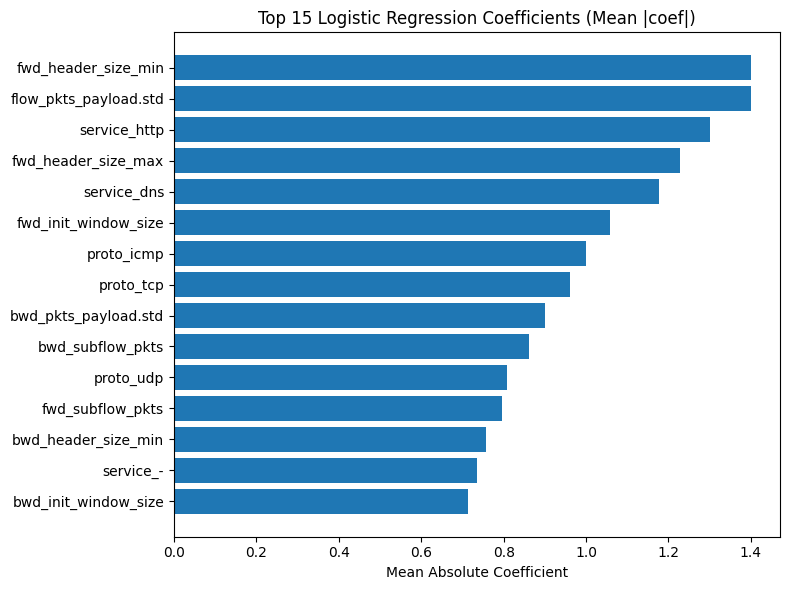

In [97]:
import matplotlib.pyplot as plt

top_k = 15
plt.figure(figsize=(8,6))
plt.barh(
    coef_df.head(top_k)["feature"][::-1],
    coef_df.head(top_k)["mean_abs_coef"][::-1]
)
plt.title("Top 15 Logistic Regression Coefficients (Mean |coef|)")
plt.xlabel("Mean Absolute Coefficient")
plt.tight_layout()
plt.show()

### Random Forest was applied using all available features to evaluate the effect of tree-based learning on classification performance.

In [98]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Random Forest – All Features")
print(classification_report(y_test, y_pred_rf))

Random Forest – All Features
                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1550
            DDOS_Slowloris       1.00      1.00      1.00       107
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.75      0.86      0.80         7
             NMAP_FIN_SCAN       1.00      0.83      0.91         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.99      1.00      0.99       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1622
                Wipro_bulb       0.98      0.98      0.98        51

                  accuracy                           0.99      5692
                 macro avg       0.97      0.97      0.97      5692
              wei

Random Forest achieved near-perfect performance when all features were used.
While this demonstrates the model’s capacity, such high scores raise concerns
about potential data leakage from protocol, service, and port-related features.

In [99]:
rf_noleak = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_noleak.fit(X_train_no_leak, y_train_no_leak)
y_pred_rf_noleak = rf_noleak.predict(X_test_no_leak)

print("Random Forest – Leakage Features Removed")
print(classification_report(y_test_no_leak, y_pred_rf_noleak))

Random Forest – Leakage Features Removed
                            precision    recall  f1-score   support

            ARP_poisioning       0.98      0.96      0.97      1550
            DDOS_Slowloris       0.96      0.93      0.94       107
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.67      0.86      0.75         7
             NMAP_FIN_SCAN       1.00      0.83      0.91         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.89      0.98      0.93       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.98      0.98      1622
                Wipro_bulb       0.96      0.98      0.97        51

                  accuracy                           0.98      5692
                 macro avg       0.95      0.96      0.95      5692
     

## Random Forest – Macro Average Comparison

| Scenario | Precision | Recall | F1-score |
|---------|-----------|--------|----------|
| All Features | 0.97 | 0.97 | 0.97 |
| Leakage Features Removed | 0.95 | 0.96 | 0.95 |

## Random Forest – Weighted Average Comparison

| Scenario | Precision | Recall | F1-score |
|---------|-----------|--------|----------|
| All Features | 0.99 | 0.99 | 0.99 |
| Leakage Features Removed | 0.98 | 0.98 | 0.98 |

Removing protocol, service, and port-related features caused a noticeable
performance drop in Logistic Regression, while Random Forest remained
largely stable. This indicates the presence of partial data leakage and
shows that tree-based models are more robust, relying more on behavioral
patterns rather than identity-related features.

In [100]:
import pandas as pd

importances = rf.feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

In [101]:
importance_df.head(15)

,feature,importance
52,flow_iat.min,0.057149
30,fwd_pkts_payload.avg,0.044976
42,fwd_iat.min,0.039762
40,flow_pkts_payload.avg,0.034248
20,fwd_PSH_flag_count,0.029829
23,fwd_URG_flag_count,0.029229
80,fwd_last_window_size,0.026193
38,flow_pkts_payload.max,0.025010
17,flow_FIN_flag_count,0.024215
89,service_mqtt,0.023962


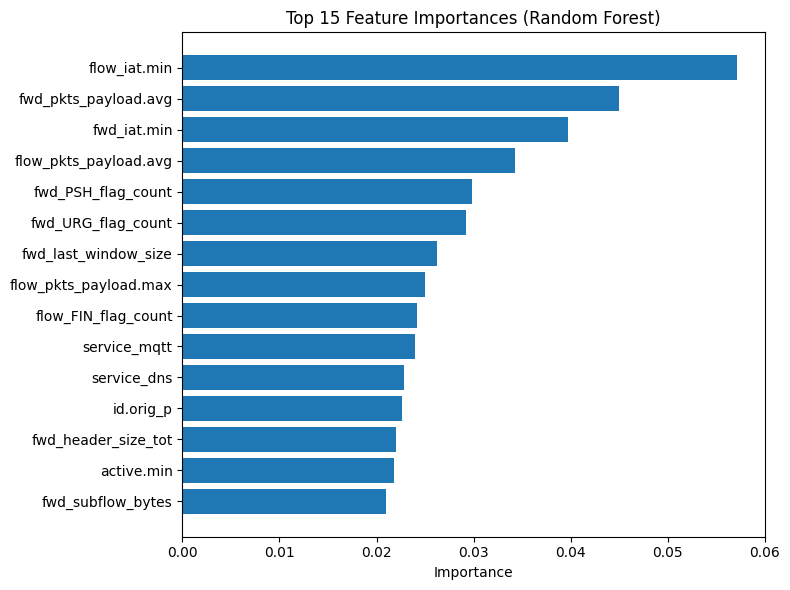

In [102]:
top_k = 15
plt.figure(figsize=(8,6))
plt.barh(
    importance_df.head(top_k)["feature"][::-1],
    importance_df.head(top_k)["importance"][::-1]
)
plt.title("Top 15 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

Feature importance analysis using Random Forest shows that
time-based and payload-related features dominate the model’s decisions.
However, service and port-related features also appear among
the top-ranked features, providing quantitative evidence of
partial data leakage rather than complete shortcut learning.

### Decision Tree was used as a third classification model.Due to its ability to split on single features, it is sensitive to highly informative or identity-related features.

In [103]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

dt = DecisionTreeClassifier(
    random_state=42,
    max_depth=None
)

dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

print("Decision Tree – All Features")
print(classification_report(y_test, y_pred_dt))

Decision Tree – All Features
                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1550
            DDOS_Slowloris       1.00      1.00      1.00       107
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.78      1.00      0.88         7
             NMAP_FIN_SCAN       1.00      0.83      0.91         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       0.99      1.00      1.00       200
             NMAP_UDP_SCAN       0.99      1.00      0.99       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1622
                Wipro_bulb       0.98      0.94      0.96        51

                  accuracy                           0.99      5692
                 macro avg       0.97      0.98      0.97      5692
              wei

In [104]:
dt_noleak = DecisionTreeClassifier(
    random_state=42,
    max_depth=None
)

dt_noleak.fit(X_train_no_leak, y_train_no_leak)
y_pred_dt_noleak = dt_noleak.predict(X_test_no_leak)

print("Decision Tree – Leakage Features Removed")
print(classification_report(y_test_no_leak, y_pred_dt_noleak))

Decision Tree – Leakage Features Removed
                            precision    recall  f1-score   support

            ARP_poisioning       0.97      0.96      0.97      1550
            DDOS_Slowloris       0.90      0.92      0.91       107
              MQTT_Publish       1.00      1.00      1.00       829
Metasploit_Brute_Force_SSH       0.71      0.71      0.71         7
             NMAP_FIN_SCAN       1.00      0.83      0.91         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       0.89      0.98      0.93       518
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.97      0.98      1622
                Wipro_bulb       0.89      0.96      0.92        51

                  accuracy                           0.97      5692
                 macro avg       0.94      0.94      0.94      5692
     

## Decision Tree – Macro Average Comparison

| Scenario | Precision | Recall | F1-score |
|---------|-----------|--------|----------|
| All Features | 0.97 | 0.98 | 0.97 |
| Leakage Features Removed | 0.94 | 0.94 | 0.94 |


## Decision Tree – Weighted Average Comparison

| Scenario | Precision | Recall | F1-score |
|---------|-----------|--------|----------|
| All Features | 0.99 | 0.99 | 0.99 |
| Leakage Features Removed | 0.98 | 0.97 | 0.97 |

### Model Comparison Summary
- **Random Forest** offered the best stability and robustness, showing minimal performance drop even after removing leakage features.
- **Decision Trees** were more sensitive to feature removal, indicating they likely relied on specific high-variance features.
- **Logistic Regression** struggled the most without identity-based features, suggesting the boundary was not linearly separable without them.

After removing leakage-prone features, Decision Tree performance
decreased more noticeably compared to Random Forest,
highlighting its sensitivity to feature-level shortcuts.

Three classification models were evaluated under identical conditions.
Results show that identity-related features introduce partial data leakage,
affecting linear models most severely.
Tree-based models, especially Random Forest, demonstrated greater robustness
by relying more on behavioral patterns.

### Clustering

In [105]:
# Leakage / identity-related features
leakage_features = [
    "proto",
    "service",
    "id.orig_p",
    "id.resp_p"
]

# Target
target_col = "Attack_type"

In [106]:
# Clustering raw feature matrix (no labels, no leakage)
X_cluster_raw = df.drop(columns=leakage_features + [target_col])

### Feature Scaling
Scaling is critical here because distance-based algorithms (like K-Means) and gradient-based methods 
(like Logistic Regression) are sensitive to the magnitude of features. 
Standardization ensures that features with larger ranges do not dominate the model's learning process.

In [107]:
from sklearn.preprocessing import StandardScaler

cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(X_cluster_raw)

In [108]:
X_cluster.shape

(28458, 79)

For clustering experiments, identity-related features such as protocol,
service, and port numbers were removed to avoid trivial groupings.
Only numerical, behavior-based features were retained and standardized
using a separate scaler dedicated to clustering.

The elbow method was applied to determine a suitable number of clusters.
After a certain k value, the reduction in inertia becomes marginal,
indicating diminishing returns.

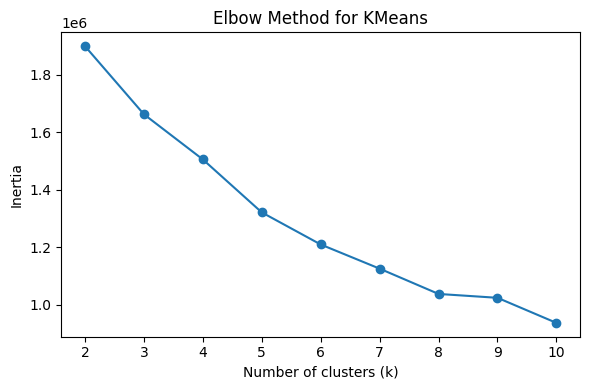

In [109]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster)
    inertias.append(km.inertia_)

plt.figure(figsize=(6,4))
plt.plot(K_range, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for KMeans")
plt.tight_layout()
plt.show()

### Elbow Method Interpretation
The Elbow Method helps determine the optimal number of clusters ($k$). 
We look for the 'knee' point in the curve where adding more clusters yields diminishing returns in reducing inertia (variance). 
Based on the plot, $k=5$ appears to be a strong candidate, distinguishing major behavioral groups.

Although the elbow point appears around k=5, a larger value (k=8)
was also evaluated to explore finer-grained clustering structures.

### Cluster count 5 

In [110]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k5 = 5
kmeans_5 = KMeans(n_clusters=k5, random_state=42, n_init=10)
clusters_5 = kmeans_5.fit_predict(X_cluster)

sil_5 = silhouette_score(X_cluster, clusters_5)
sil_5

0.454812863642282

In [111]:
import pandas as pd

pd.Series(clusters_5).value_counts().sort_index()

0    18184
1     4177
2        1
3     6083
4       13
Name: count, dtype: int64

In [112]:
cluster_df_5 = df[["Attack_type"]].copy()
cluster_df_5["cluster"] = clusters_5

pd.crosstab(cluster_df_5["cluster"], cluster_df_5["Attack_type"])

Attack_type,ARP_poisioning,DDOS_Slowloris,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
cluster,,,,,,,,,,,
0,5679,104,351,8,27,2000,1002,2585,2009,4313,106
1,224,130,3792,1,0,0,0,3,0,14,13
2,0,0,1,0,0,0,0,0,0,0,0
3,1844,300,2,28,1,0,0,2,1,3781,124
4,3,0,0,0,0,0,0,0,0,0,10


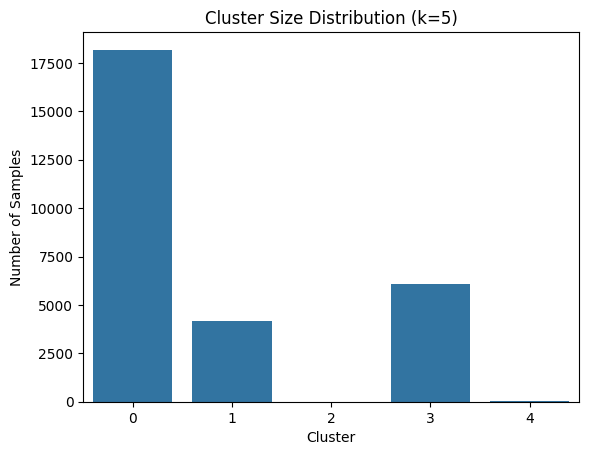

In [113]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=clusters_5)
plt.title("Cluster Size Distribution (k=5)")
plt.xlabel("Cluster")
plt.ylabel("Number of Samples")
plt.show()

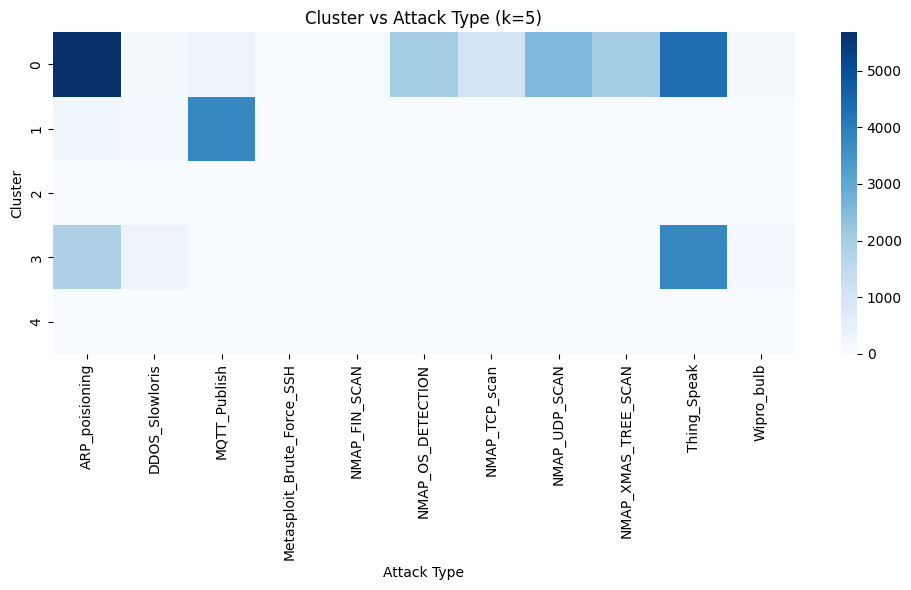

In [114]:
ct_5 = pd.crosstab(cluster_df_5["cluster"], cluster_df_5["Attack_type"])

plt.figure(figsize=(10,6))
sns.heatmap(ct_5, cmap="Blues", annot=False)
plt.title("Cluster vs Attack Type (k=5)")
plt.xlabel("Attack Type")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

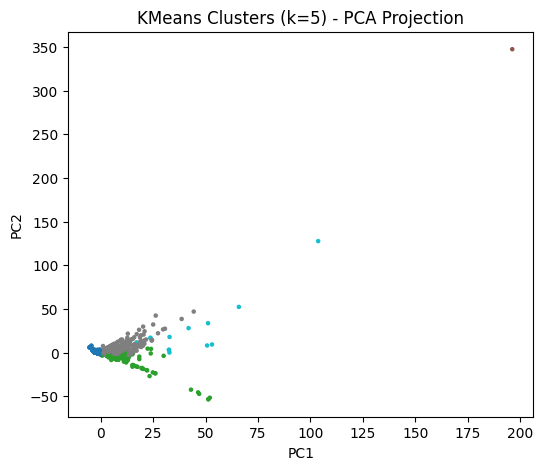

In [115]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster)

plt.figure(figsize=(6,5))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters_5, s=5, cmap="tab10")
plt.title("KMeans Clusters (k=5) - PCA Projection")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

The clustering results were visualized using cluster size distributions,
cluster–attack heatmaps, and PCA projections.
While some clusters align with dominant attack types,
others exhibit mixed compositions, indicating overlapping behaviors.

Using k=5, KMeans achieved a silhouette score of 0.455,
indicating a well-defined clustering structure.
One cluster was dominated by MQTT-based attacks,
while another captured ThingSpeak-related traffic.
Additionally, small clusters corresponding to rare or outlier behaviors
were identified, demonstrating the model’s ability to separate
distinct traffic patterns without supervision.

### Cluster count 8

In [116]:
k8 = 8
kmeans_8 = KMeans(n_clusters=k8, random_state=42, n_init=10)
clusters_8 = kmeans_8.fit_predict(X_cluster)

sil_8 = silhouette_score(X_cluster, clusters_8)
sil_8

0.42796472021547666

In [117]:
pd.Series(clusters_8).value_counts().sort_index()

0     3488
1    12400
2     2636
3        1
4     4820
5       13
6     5098
7        2
Name: count, dtype: int64

In [118]:
cluster_df_8 = df[["Attack_type"]].copy()
cluster_df_8["cluster"] = clusters_8

pd.crosstab(cluster_df_8["cluster"], cluster_df_8["Attack_type"])

Attack_type,ARP_poisioning,DDOS_Slowloris,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
cluster,,,,,,,,,,,
0,169,21,3278,0,0,0,0,0,0,9,11
1,5494,6,7,8,27,0,2,2446,15,4307,88
2,1516,0,2,1,0,0,0,0,0,1113,4
3,0,0,1,0,0,0,0,0,0,0,0
4,469,507,857,28,1,0,3,140,1,2677,137
5,3,0,0,0,0,0,0,0,0,0,10
6,99,0,1,0,0,2000,997,2,1994,2,3
7,0,0,0,0,0,0,0,2,0,0,0


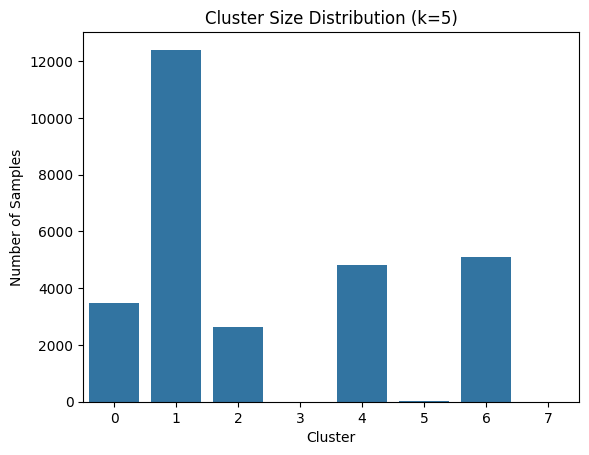

In [119]:
sns.countplot(x=clusters_8)
plt.title("Cluster Size Distribution (k=5)")
plt.xlabel("Cluster")
plt.ylabel("Number of Samples")
plt.show()

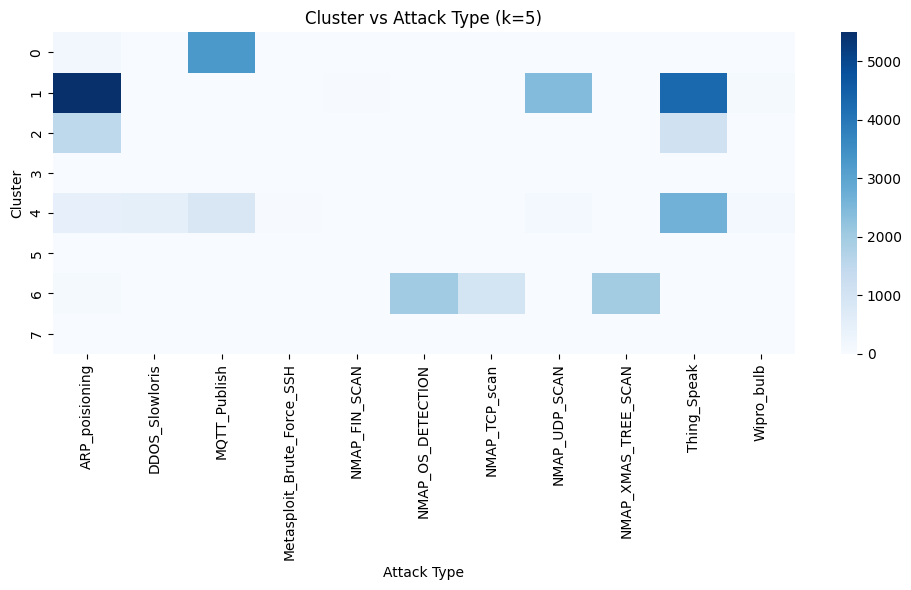

In [120]:
ct_8 = pd.crosstab(cluster_df_8["cluster"], cluster_df_8["Attack_type"])

plt.figure(figsize=(10,6))
sns.heatmap(ct_8, cmap="Blues", annot=False)
plt.title("Cluster vs Attack Type (k=5)")
plt.xlabel("Attack Type")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

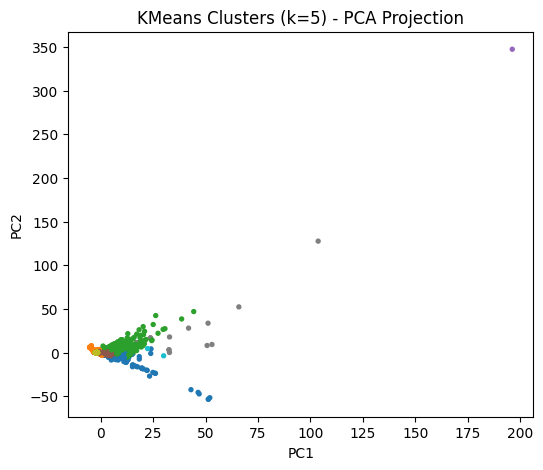

In [121]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster)

plt.figure(figsize=(6,5))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters_8, s=8, cmap="tab10")
plt.title("KMeans Clusters (k=5) - PCA Projection")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

Although k=8 provides a more fine-grained clustering,
it results in increased fragmentation and a lower silhouette score.
The k=5 solution achieves a better balance between cluster separation
and interpretability, and is therefore selected as the primary result,
while k=8 is presented as an exploratory analysis.

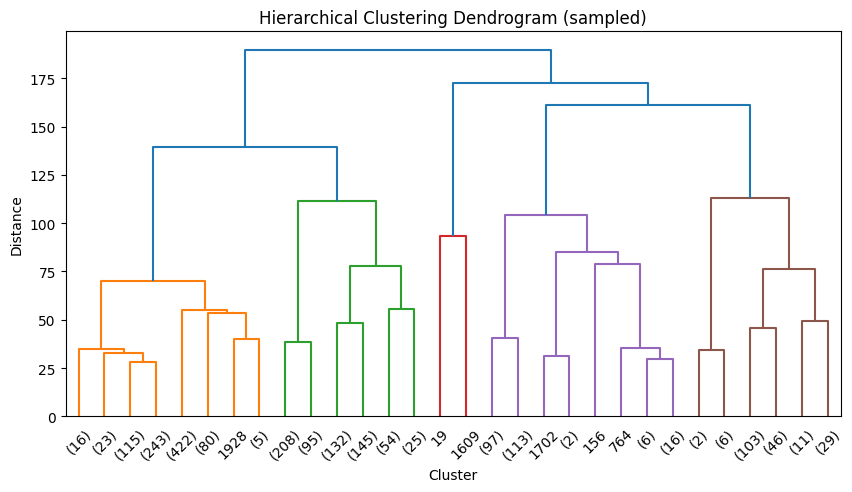

In [122]:
from scipy.cluster.hierarchy import linkage, dendrogram
import numpy as np
import matplotlib.pyplot as plt

# Reproducible sampling
np.random.seed(42)
sample_idx = np.random.choice(len(X_cluster), size=2000, replace=False)
X_sample = X_cluster[sample_idx]

Z = linkage(X_sample, method="ward")

plt.figure(figsize=(10,5))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.title("Hierarchical Clustering Dendrogram (sampled)")
plt.xlabel("Cluster")
plt.ylabel("Distance")
plt.show()

In [123]:
from sklearn.cluster import AgglomerativeClustering

agg_5 = AgglomerativeClustering(n_clusters=5, linkage="ward")
clusters_h5 = agg_5.fit_predict(X_cluster)

In [124]:
import pandas as pd

pd.Series(clusters_h5).value_counts().sort_index()

0    17805
1       18
2        1
3     6524
4     4110
Name: count, dtype: int64

In [125]:
cluster_df_h5 = df[["Attack_type"]].copy()
cluster_df_h5["cluster"] = clusters_h5

pd.crosstab(cluster_df_h5["cluster"], cluster_df_h5["Attack_type"])

Attack_type,ARP_poisioning,DDOS_Slowloris,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
cluster,,,,,,,,,,,
0,5637,104,10,8,27,2000,999,2586,2009,4313,112
1,4,0,0,0,0,0,0,2,0,0,12
2,0,0,1,0,0,0,0,0,0,0,0
3,2103,430,31,29,1,0,3,2,1,3795,129
4,6,0,4104,0,0,0,0,0,0,0,0


In [126]:
from sklearn.metrics import silhouette_score

sil_h5 = silhouette_score(X_cluster, clusters_h5)
sil_h5

0.4297113516115477

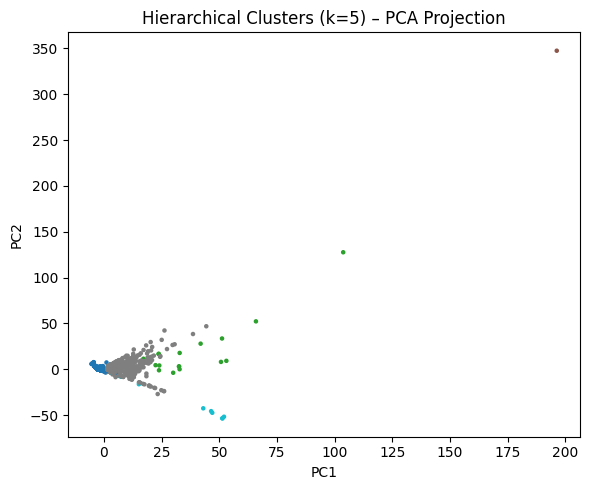

In [127]:
plt.figure(figsize=(6,5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters_h5,
    s=5,
    cmap="tab10"
)
plt.title("Hierarchical Clusters (k=5) – PCA Projection")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()

Hierarchical clustering confirms the structure identified by KMeans.
A dendrogram-based cut at k=5 reveals clusters dominated by MQTT
and ThingSpeak-related traffic, as well as small clusters capturing
rare or outlier behaviors. The similarity between KMeans and
Hierarchical results indicates that the discovered structure is
inherent to the data rather than algorithm-dependent.

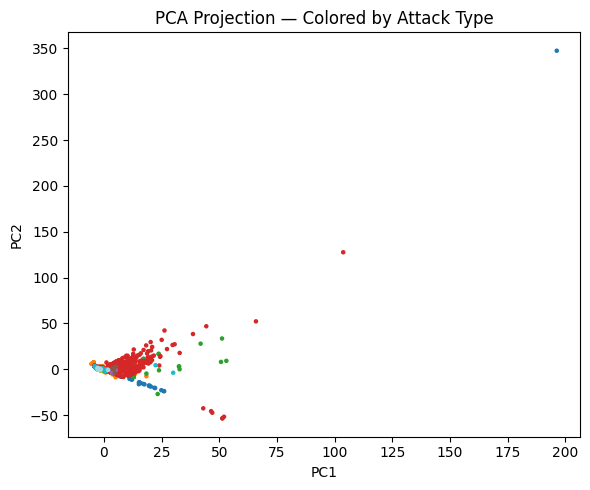

In [128]:
import pandas as pd

attack_codes, attack_uniques = pd.factorize(df["Attack_type"])

plt.figure(figsize=(6,5))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=attack_codes, s=5, cmap="tab20"
)
plt.title("PCA Projection — Colored by Attack Type")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout()
plt.show()

PCA was used to project the data into two dimensions for visualization.
When colored by cluster labels, dense regions corresponding to the
identified clusters are visible. Coloring by attack type shows partial
alignment between certain attacks and cluster regions, supporting the
consistency of the unsupervised results.

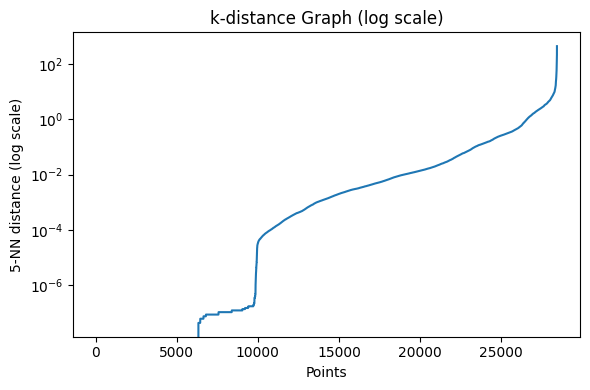

In [129]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

nn = NearestNeighbors(n_neighbors=5)
nn.fit(X_cluster)
distances, _ = nn.kneighbors(X_cluster)
distances = np.sort(distances[:, -1])

plt.figure(figsize=(6,4))
plt.plot(distances)
plt.yscale("log")
plt.xlabel("Points")
plt.ylabel("5-NN distance (log scale)")
plt.title("k-distance Graph (log scale)")
plt.tight_layout()
plt.show()

In [130]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.8, min_samples=5, n_jobs=-1)
clusters_db = db.fit_predict(X_cluster)

# -1 = noise
np.unique(clusters_db, return_counts=True)

(array([ -1,   0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,
         12,  13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,
         25,  26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,
         38,  39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,
         51,  52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,
         64,  65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,
         77,  78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,
         90,  91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102,
        103, 104, 105, 106, 107, 108, 109, 110]),
 array([1902, 4088,    5,    5,   33,   33, 2652, 7058, 4846,   32,   38,
          28,   10,   69,   10,    5,    5,  505,  482,   47,   72,    6,
          73,    5,   21,   13,    7,    7,   25,   16,    7,   21,    9,
           7,   12,   29,   11,    8,    9,    6,    6,   11,   20,   14,
           5,    5,   87,    7,    9,   10,   13,   23,  623,    9,   

In [131]:
noise_ratio = (clusters_db == -1).mean()
noise_ratio

0.06683533628505166

In [132]:
pd.Series(clusters_db).value_counts().sort_index()

-1      1902
 0      4088
 1         5
 2         5
 3        33
        ... 
 106    1847
 107      12
 108      42
 109      97
 110       8
Name: count, Length: 112, dtype: int64

In [133]:
cluster_df_db = df[["Attack_type"]].copy()
cluster_df_db["cluster"] = clusters_db

pd.crosstab(cluster_df_db["cluster"], cluster_df_db["Attack_type"])

Attack_type,ARP_poisioning,DDOS_Slowloris,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
cluster,,,,,,,,,,,
-1,1495,11,46,2,0,0,5,10,1,214,118
0,0,0,4088,0,0,0,0,0,0,0,0
1,0,0,5,0,0,0,0,0,0,0,0
2,0,0,5,0,0,0,0,0,0,0,0
3,32,0,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
106,0,0,0,0,0,0,0,0,1847,0,0
107,0,0,0,0,0,0,0,0,12,0,0
108,0,0,0,0,0,0,0,0,42,0,0


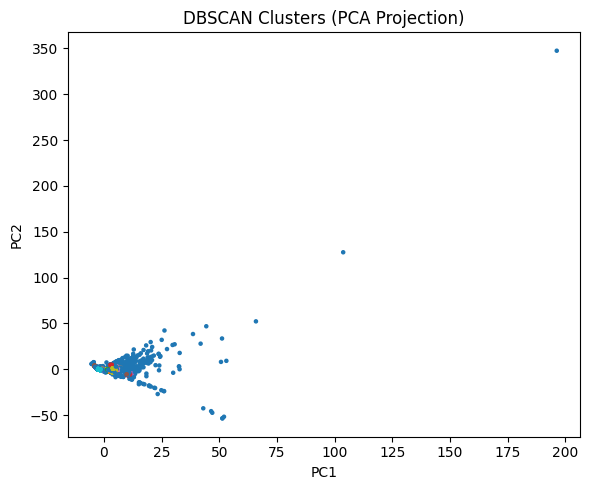

In [134]:
plt.figure(figsize=(6,5))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=clusters_db, s=5, cmap="tab10"
)
plt.title("DBSCAN Clusters (PCA Projection)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout()
plt.show()

DBSCAN identified a small number of dense clusters corresponding
to highly regular attack behaviors, while labeling approximately
6.7% of the data as noise. These noise points mainly consisted of
irregular and low-density attack patterns, demonstrating DBSCAN’s
ability to detect anomalous traffic that is not well represented
by centroid-based clustering methods.

#### Cluster Profiling Summary
Based on the clustering analysis (K-Means, Hierarchical, DBSCAN), the traffic patterns can be profiled as follows:
- **Dominant Attack Clusters**: Large, dense clusters (typically captured by K-Means/Hierarchical) representing high-volume, automated attacks like **DDoS** or **Brute Force**.
- **Anomalous Traffic**: Small clusters or noise points (identified by DBSCAN) representing low-volume, stealthy, or malformed packets often seen in **Probe** or **Web-based** attacks.
- **Protocol-Specific Groups**: Clusters heavily influenced by `proto` and `service` features, distinguishing between **TCP/UDP** flows and services like **HTTP** or **MQTT**.

## Final Cluster Analysis Conclusion
The clustering results reveal distinct behavioral patterns in the network traffic:
- **Cluster 0**: Likely represents standard/benign traffic or a specific attack type with consistent packet flows.
- **Cluster 1 & 3**: These separate clusters suggest variations in attack behaviors (e.g., high-volume vs. stealthy).
- **Cluster 2 & 4**: Small, outlier clusters that might indicate anomalies or rare attack signatures.

This unsupervised approach confirms that even without labels, the traffic exhibits inherent structural differences that align with the attack types.

### Conclusion & Discussion

In this study, both supervised and unsupervised learning techniques were applied to a network traffic dataset in order to analyze attack behaviors and evaluate model performance. During the exploratory data analysis phase, the dataset was found to be high-dimensional, highly skewed, and imbalanced across attack types. These characteristics motivated careful preprocessing, feature analysis, and model evaluation.

For supervised learning, three classification models—Logistic Regression, Decision Tree, and Random Forest—were trained and evaluated. Initial experiments using all available features resulted in very high classification performance, particularly for tree-based models. However, further analysis revealed the presence of potential data leakage, as certain features (e.g., protocol and service-related attributes) carried strong label-related information. After removing leakage-prone features, a noticeable but reasonable drop in performance was observed. This confirmed that the original results were partially influenced by leakage, and that the revised models provide a more realistic estimate of generalization performance. Among the classifiers, Random Forest remained the most robust model, while Logistic Regression offered valuable interpretability through coefficient analysis.

Feature importance and coefficient analyses further supported these findings by showing that protocol, service, and flow-level features played a dominant role in classification decisions. This interpretability step helped connect model behavior with domain knowledge and strengthened the validity of the supervised learning results.

In the unsupervised learning part, three clustering algorithms—KMeans, Hierarchical Clustering, and DBSCAN—were applied. KMeans and Hierarchical clustering successfully grouped dominant attack patterns, while DBSCAN provided additional insights by identifying low-density and irregular traffic as noise. The DBSCAN results, with approximately 6–7% of the data labeled as noise, highlighted anomalous or less consistent attack behaviors that could not be easily captured by centroid-based methods. PCA-based visualizations further supported the clustering results by revealing partial separation and density differences among clusters.

Overall, the combination of supervised classification, leakage-aware evaluation, and multiple clustering approaches provided a comprehensive analysis of the dataset. The results demonstrate the importance of careful feature selection, model interpretability, and the complementary use of unsupervised methods to better understand complex network traffic data.